## Aim

When I find something interesting, I feel like trying it out.

I had never heard of the "Source Cooperative" and for this talk I wanted to try it out.

Doing this, I realised that while doing this the concept of "lazy evaluation" can be illustrated.

This means that unless you actually tell the program to call/load the data, you are just trying to understand and browse it.

Here, we will see that although we followed the tutorial strictly given by the original data source, we ran into issues as the plot crashed (due to RAM).

The data is from here. The code from this website  is followed but some (minor) changes are done (mainly for the plotting) and extracting the data for Europe only.

The references you can find below of this script.

Looks like a json data!

Hmm never handled this one in xarray!

In [3]:
from pystac import Item
from odc.stac import load

path = "https://data.source.coop/ausantarctic/ghrsst-mur-v2/2025/02/09/20250209090000-JPL-L4_GHRSST-SSTfnd-MUR-GLOB-v02.0-fv04.1.stac-item.json"
item = Item.from_file(path)

data = load([item], chunks={}, anchor="center")
data

<xarray.Dataset> Size: 5GB
Dimensions:           (latitude: 17999, longitude: 36000, time: 1)
Coordinates:
  * latitude          (latitude) float64 144kB 89.99 89.98 ... -89.98 -89.99
  * longitude         (longitude) float64 288kB -180.0 -180.0 ... 180.0 180.0
  * time              (time) datetime64[ns] 8B 2025-02-09
    spatial_ref       int32 4B 4326
Data variables:
    analysed_sst      (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    analysis_error    (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    mask              (time, latitude, longitude) int8 648MB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    sea_ice_fraction  (time, latitude, longitude) int8 648MB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    sst_anomaly       (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>

You can see that the chunks are too big so that will not work well.

In [4]:
sst_loaded_temp = data["analysed_sst"]
sst_loaded_temp

<xarray.DataArray 'analysed_sst' (time: 1, latitude: 17999, longitude: 36000)> Size: 1GB
dask.array<analysed_sst, shape=(1, 17999, 36000), dtype=int16, chunksize=(1, 17999, 36000), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 8B 2025-02-09
  * latitude     (latitude) float64 144kB 89.99 89.98 89.97 ... -89.98 -89.99
  * longitude    (longitude) float64 288kB -180.0 -180.0 -180.0 ... 180.0 180.0
    spatial_ref  int32 4B 4326
Attributes:
    nodata:   -32768

If you execute the following code, Google Colab crashes ...

This code is directly given in the COOP website itself!

In [ ]:
## Code example is given in the
sst_loaded = data["analysed_sst"].squeeze().compute()
sst_masked = sst_loaded.where(sst_loaded != -32768)

# Extract the scale and offset from the metadata
meta = item.assets["analysed_sst"].extra_fields["raster:bands"][0]
scale = meta["scale"]
offset = meta["offset"]

sst_scaled = sst_masked * scale + offset  # degrees Celsius
sst_scaled.plot.imshow(size=8, robust=True, cmap="inferno")

In [5]:
print(data)
print(data.dims)
print(data.coords)
print(data.data_vars)

<xarray.Dataset> Size: 5GB
Dimensions:           (latitude: 17999, longitude: 36000, time: 1)
Coordinates:
  * latitude          (latitude) float64 144kB 89.99 89.98 ... -89.98 -89.99
  * longitude         (longitude) float64 288kB -180.0 -180.0 ... 180.0 180.0
  * time              (time) datetime64[ns] 8B 2025-02-09
    spatial_ref       int32 4B 4326
Data variables:
    analysed_sst      (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    analysis_error    (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    mask              (time, latitude, longitude) int8 648MB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    sea_ice_fraction  (time, latitude, longitude) int8 648MB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
    sst_anomaly       (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>
FrozenMappingWarningOnValuesAccess({'lati

In [8]:
data.chunks

Frozen({'time': (1,), 'latitude': (17999,), 'longitude': (36000,)})

Hughe!

Can we take a smaller area?

In [10]:
sst = data[["analysed_sst"]]
sst

<xarray.Dataset> Size: 1GB
Dimensions:       (time: 1, latitude: 17999, longitude: 36000)
Coordinates:
  * time          (time) datetime64[ns] 8B 2025-02-09
  * latitude      (latitude) float64 144kB 89.99 89.98 89.97 ... -89.98 -89.99
  * longitude     (longitude) float64 288kB -180.0 -180.0 -180.0 ... 180.0 180.0
    spatial_ref   int32 4B 4326
Data variables:
    analysed_sst  (time, latitude, longitude) int16 1GB dask.array<chunksize=(1, 17999, 36000), meta=np.ndarray>

The following does not work. It is not in the metadata.

In [14]:
sst.encoding['chunks']

KeyError: 'chunks'

In [17]:
sst.chunks

Frozen({'time': (1,), 'latitude': (17999,), 'longitude': (36000,)})

In [19]:
sst_europe = sst.sel(
    latitude=slice(72, 34),
    longitude=slice(-25, 45)
)
sst_europe

<xarray.Dataset> Size: 53MB
Dimensions:       (time: 1, latitude: 3801, longitude: 7001)
Coordinates:
  * time          (time) datetime64[ns] 8B 2025-02-09
  * latitude      (latitude) float64 30kB 72.0 71.99 71.98 ... 34.02 34.01 34.0
  * longitude     (longitude) float64 56kB -25.0 -24.99 -24.98 ... 44.99 45.0
    spatial_ref   int32 4B 4326
Data variables:
    analysed_sst  (time, latitude, longitude) int16 53MB dask.array<chunksize=(1, 3801, 7001), meta=np.ndarray>

Let's call the data now. Till now, there was no loading of the data. You can do so with "compute()" or "load()":

In [20]:
sst_europe = sst_europe.compute()

In [22]:
sst_europe

<xarray.Dataset> Size: 53MB
Dimensions:       (time: 1, latitude: 3801, longitude: 7001)
Coordinates:
  * time          (time) datetime64[ns] 8B 2025-02-09
  * latitude      (latitude) float64 30kB 72.0 71.99 71.98 ... 34.02 34.01 34.0
  * longitude     (longitude) float64 56kB -25.0 -24.99 -24.98 ... 44.99 45.0
    spatial_ref   int32 4B 4326
Data variables:
    analysed_sst  (time, latitude, longitude) int16 53MB -32768 ... -32768

In [23]:
import matplotlib.pyplot as plt


In [27]:
sst_masked = sst_europe.where(sst_europe != -32768)

# Extract the scale and offset from the metadata
meta = item.assets["analysed_sst"].extra_fields["raster:bands"][0]
scale = meta["scale"]
offset = meta["offset"]

sst_scaled = sst_masked * scale + offset  # degrees Celsius
sst_scaled.plot.imshow(size=8, robust=True, cmap="inferno")

AttributeError: 'DatasetPlotAccessor' object has no attribute 'imshow'

Hmm, this is because the dataset is still in a Dataset.

Let's fix it:

In [28]:
sst_europe

<xarray.Dataset> Size: 53MB
Dimensions:       (time: 1, latitude: 3801, longitude: 7001)
Coordinates:
  * time          (time) datetime64[ns] 8B 2025-02-09
  * latitude      (latitude) float64 30kB 72.0 71.99 71.98 ... 34.02 34.01 34.0
  * longitude     (longitude) float64 56kB -25.0 -24.99 -24.98 ... 44.99 45.0
    spatial_ref   int32 4B 4326
Data variables:
    analysed_sst  (time, latitude, longitude) int16 53MB -32768 ... -32768

In [ ]:
## Convert to a data array:

In [29]:
sst_scaled

<xarray.Dataset> Size: 107MB
Dimensions:       (latitude: 3801, longitude: 7001, time: 1)
Coordinates:
  * latitude      (latitude) float64 30kB 72.0 71.99 71.98 ... 34.02 34.01 34.0
  * longitude     (longitude) float64 56kB -25.0 -24.99 -24.98 ... 44.99 45.0
  * time          (time) datetime64[ns] 8B 2025-02-09
    spatial_ref   int32 4B 4326
Data variables:
    analysed_sst  (time, latitude, longitude) float32 106MB nan nan ... nan nan

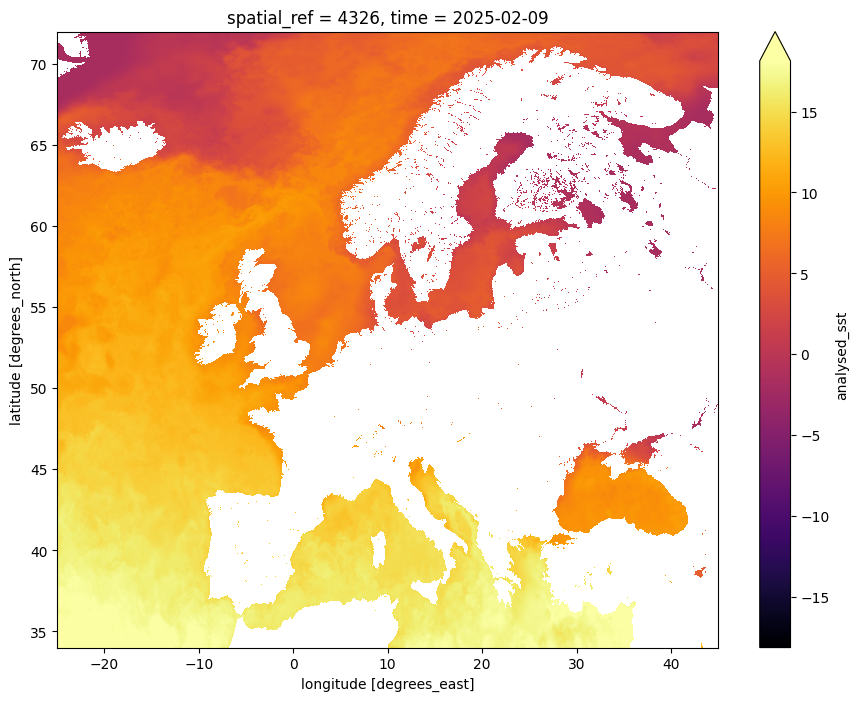

In [31]:
# Exact code from:
# https://source.coop/ausantarctic/ghrsst-mur-v2
sst_scaled = sst_scaled.squeeze("time")

sst_scaled.plot.imshow(
    size=8,
    robust=True,
    cmap="inferno"
)

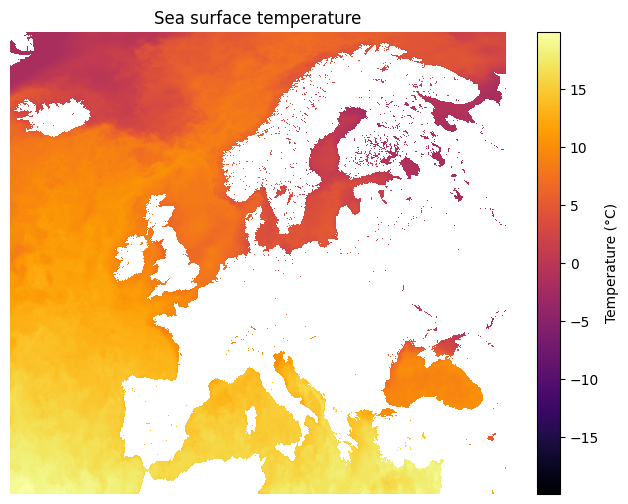

In [45]:
plt.figure(figsize=(8, 6))
sst_scaled.plot(
    cmap='inferno',
    cbar_kwargs={'label': 'Temperature (°C)'},
)
plt.title('Sea surface temperature')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.axis('off')
plt.savefig('sea_surface_temp.png', dpi=300, bbox_inches='tight')

plt.show()

We can add more bells and whistles (we have to actually) like name, data source, etc.

## References

https://source.coop/ausantarctic/ghrsst-mur-v2